# ĐỒ ÁN CUỐI KỲ – DATA MINING
## Khai phá cấu trúc quần xã thủy sinh và phân tích mối liên hệ với điều kiện môi trường

**Mục tiêu:** Khám phá bốn bảng dữ liệu s001–s004, tích hợp dữ liệu sinh học và môi trường, xây dựng ma trận mẫu × Taxa, áp dụng K-Means và diễn giải các nhóm mẫu.

**Phạm vi:** Các bước Data Understanding, EDA, Data Integration, Preprocessing, K-Means, đánh giá và diễn giải. Không sử dụng thuật toán nâng cao; các nội dung mở rộng chỉ gồm so sánh cách biểu diễn dữ liệu, kiểm tra độ ổn định cơ bản và kiểm định thống kê mô tả.

**Sản phẩm:** Notebook phân tích và ứng dụng AquaBio Explorer (`app.py`).

## Hướng dẫn chạy

Cấu trúc thư mục:

```text
AquaBio_Explorer/
├── app.py
├── DataMining_Final_Project.ipynb
├── data/
│   ├── bdj-11-e105314-s001.csv
│   ├── bdj-11-e105314-s002.csv
│   ├── bdj-11-e105314-s003.csv
│   └── bdj-11-e105314-s004.csv
└── outputs/
```

Cài thư viện: `pip install pandas numpy matplotlib seaborn scikit-learn scipy plotly streamlit`.
Chạy notebook từ trên xuống dưới. Chạy ứng dụng bằng `streamlit run app.py`.

**Lưu ý:** Bốn CSV gốc không nằm trong hai tệp mã nguồn được cung cấp ở lượt này. Notebook và app được viết để đọc đúng tên file nêu trên; cần đặt dữ liệu gốc vào thư mục `data` trước khi chạy.

## CHƯƠNG 1. IMPORT, ĐỌC DỮ LIỆU VÀ DATA UNDERSTANDING

Mỗi bảng có đơn vị quan sát khác nhau. Không ghép dữ liệu theo số dòng; cần xác định khóa trước khi tích hợp.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
if not DATA_DIR.exists() and (BASE_DIR.parent / "data").exists():
    DATA_DIR = BASE_DIR.parent / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "s001": "bdj-11-e105314-s001.csv",
    "s002": "bdj-11-e105314-s002.csv",
    "s003": "bdj-11-e105314-s003.csv",
    "s004": "bdj-11-e105314-s004.csv",
}

def read_csv_smart(path):
    errors = []
    for encoding in ("utf-8-sig", "utf-8", "cp1252", "latin1"):
        for sep in (";", ",", "\t"):
            try:
                frame = pd.read_csv(path, sep=sep, encoding=encoding)
                if frame.shape[1] > 1:
                    frame.columns = frame.columns.astype(str).str.strip()
                    return frame
            except Exception as exc:
                errors.append(str(exc))
    raise ValueError(f"Không đọc được {path}")

data = {}
for key, filename in FILES.items():
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Thiếu {path}. Hãy đặt đủ bốn CSV trong thư mục data.")
    data[key] = read_csv_smart(path)

df_water = data["s001"].copy()
df_environment = data["s002"].copy()
df_biology = data["s003"].copy()
df_sediment = data["s004"].copy()

for name, frame in data.items():
    print(f"{name}: {frame.shape[0]:,} dòng × {frame.shape[1]} cột")

s001: 926 dòng × 21 cột
s002: 535 dòng × 28 cột
s003: 4,161 dòng × 7 cột
s004: 70 dòng × 14 cột


In [2]:
# Báo cáo chất lượng tổng quan của bốn bảng
quality_rows = []
for name, frame in data.items():
    quality_rows.append({
        "Dataset": name,
        "Rows": len(frame),
        "Columns": frame.shape[1],
        "Missing cells": int(frame.isna().sum().sum()),
        "Missing rate (%)": round(frame.isna().sum().sum() / max(frame.size, 1) * 100, 2),
        "Duplicate rows": int(frame.duplicated().sum())
    })
quality_report = pd.DataFrame(quality_rows)
display(quality_report)

# Kiểu dữ liệu, số lượng thiếu và số giá trị phân biệt theo từng biến
for name, frame in data.items():
    print(f"\n{name.upper()} – {frame.shape}")
    detail = pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing_count": frame.isna().sum(),
        "missing_percent": (frame.isna().mean() * 100).round(2),
        "n_unique": frame.nunique(dropna=True)
    }).sort_values("missing_percent", ascending=False)
    display(detail)

,Dataset,Rows,Columns,Missing cells,Missing rate (%),Duplicate rows
0,s001,926,21,4199,21.59,0
1,s002,535,28,5592,37.33,0
2,s003,4161,7,0,0.00,0
3,s004,70,14,0,0.00,0



S001 – (926, 21)


,dtype,missing_count,missing_percent,n_unique
Trans,float64,890,96.11,11
ORP,float64,887,95.79,34
pH,float64,839,90.60,65
Vel,float64,794,85.75,69
Turb,float64,789,85.21,126
Cond,float64,0,0.00,660
Dens,float64,0,0.00,217
Sal,float64,0,0.00,452
TDS,float64,0,0.00,396
SCond,float64,0,0.00,665



S002 – (535, 28)


,dtype,missing_count,missing_percent,n_unique
b.TDS,float64,486,90.84,39
s.TDS,float64,486,90.84,38
b.SPS,float64,486,90.84,48
s.SPS,float64,486,90.84,47
b.DOXS,float64,486,90.84,45
s.DOXS,float64,486,90.84,45
Trans,float64,447,83.55,20
b.pH,float64,391,73.08,70
s.pH,float64,388,72.52,68
s.DOX,float64,319,59.63,141



S003 – (4161, 7)


,dtype,missing_count,missing_percent,n_unique
Trawl,object,0,0.0,527
Waterbody,object,0,0.0,12
Depth,int64,0,0.0,29
Datetime,object,0,0.0,497
Taxa,object,0,0.0,49
Number,int64,0,0.0,225
Biomass,float64,0,0.0,3279



S004 – (70, 14)


,dtype,missing_count,missing_percent,n_unique
Station,int64,0,0.0,70
Period,object,0,0.0,22
Depth,int64,0,0.0,16
Sed1,float64,0,0.0,48
Sed2,float64,0,0.0,65
Sed3,float64,0,0.0,64
Sed4,float64,0,0.0,61
Sed5,float64,0,0.0,57
Gravel,float64,0,0.0,38
Sand,float64,0,0.0,64


### Nhận xét chất lượng dữ liệu

- Missing không mặc nhiên là 0. Với pH, DOX, Hg, độ mặn..., không thay missing bằng 0.
- Dòng trùng hoàn toàn khác với nhiều phép đo tại cùng một địa điểm hoặc thời điểm.
- Giá trị ngoại lệ cần được xem xét theo ngữ cảnh, không xóa chỉ vì nằm ngoài whisker của boxplot.
- s003 là bảng chính để xây dựng thành phần quần xã; s002 dùng cho phân tích môi trường sau phân cụm. s001 và s004 được khám phá riêng vì đơn vị quan sát/khóa không tương đồng trực tiếp với s003.

## CHƯƠNG 2. EDA – KHÁM PHÁ TỪNG DATASET

,count,mean,std,min,25%,50%,75%,max
Station,926.0,49.920086,24.596376,1.000000,31.000000,51.000000,70.000000,90.000000
Latitude,926.0,10.022119,0.239700,9.499637,9.877683,10.005850,10.249650,10.329218
Longitude,926.0,106.327262,0.223893,105.904567,106.159220,106.316583,106.526483,106.750452
Dist2mouth,926.0,33.842549,23.836917,1.200000,17.000000,30.000000,58.000000,89.000000
Depth,926.0,4.201944,3.745013,0.000000,1.000000,3.000000,6.000000,20.000000
T,926.0,29.356263,1.468118,26.700000,28.300000,29.000000,30.650000,32.500000
DOX,926.0,5.425367,0.840245,2.510000,4.870000,5.430000,6.020000,7.610000
DOXS,926.0,73.305076,12.649408,34.400000,64.425000,73.050000,81.800000,102.800000
Cond,926.0,8936.011771,11506.383700,146.600000,173.600000,2622.000000,16257.500000,32767.000000
SCond,926.0,8498.329590,11160.133113,134.900000,164.325000,2421.500000,14551.750000,32767.000000


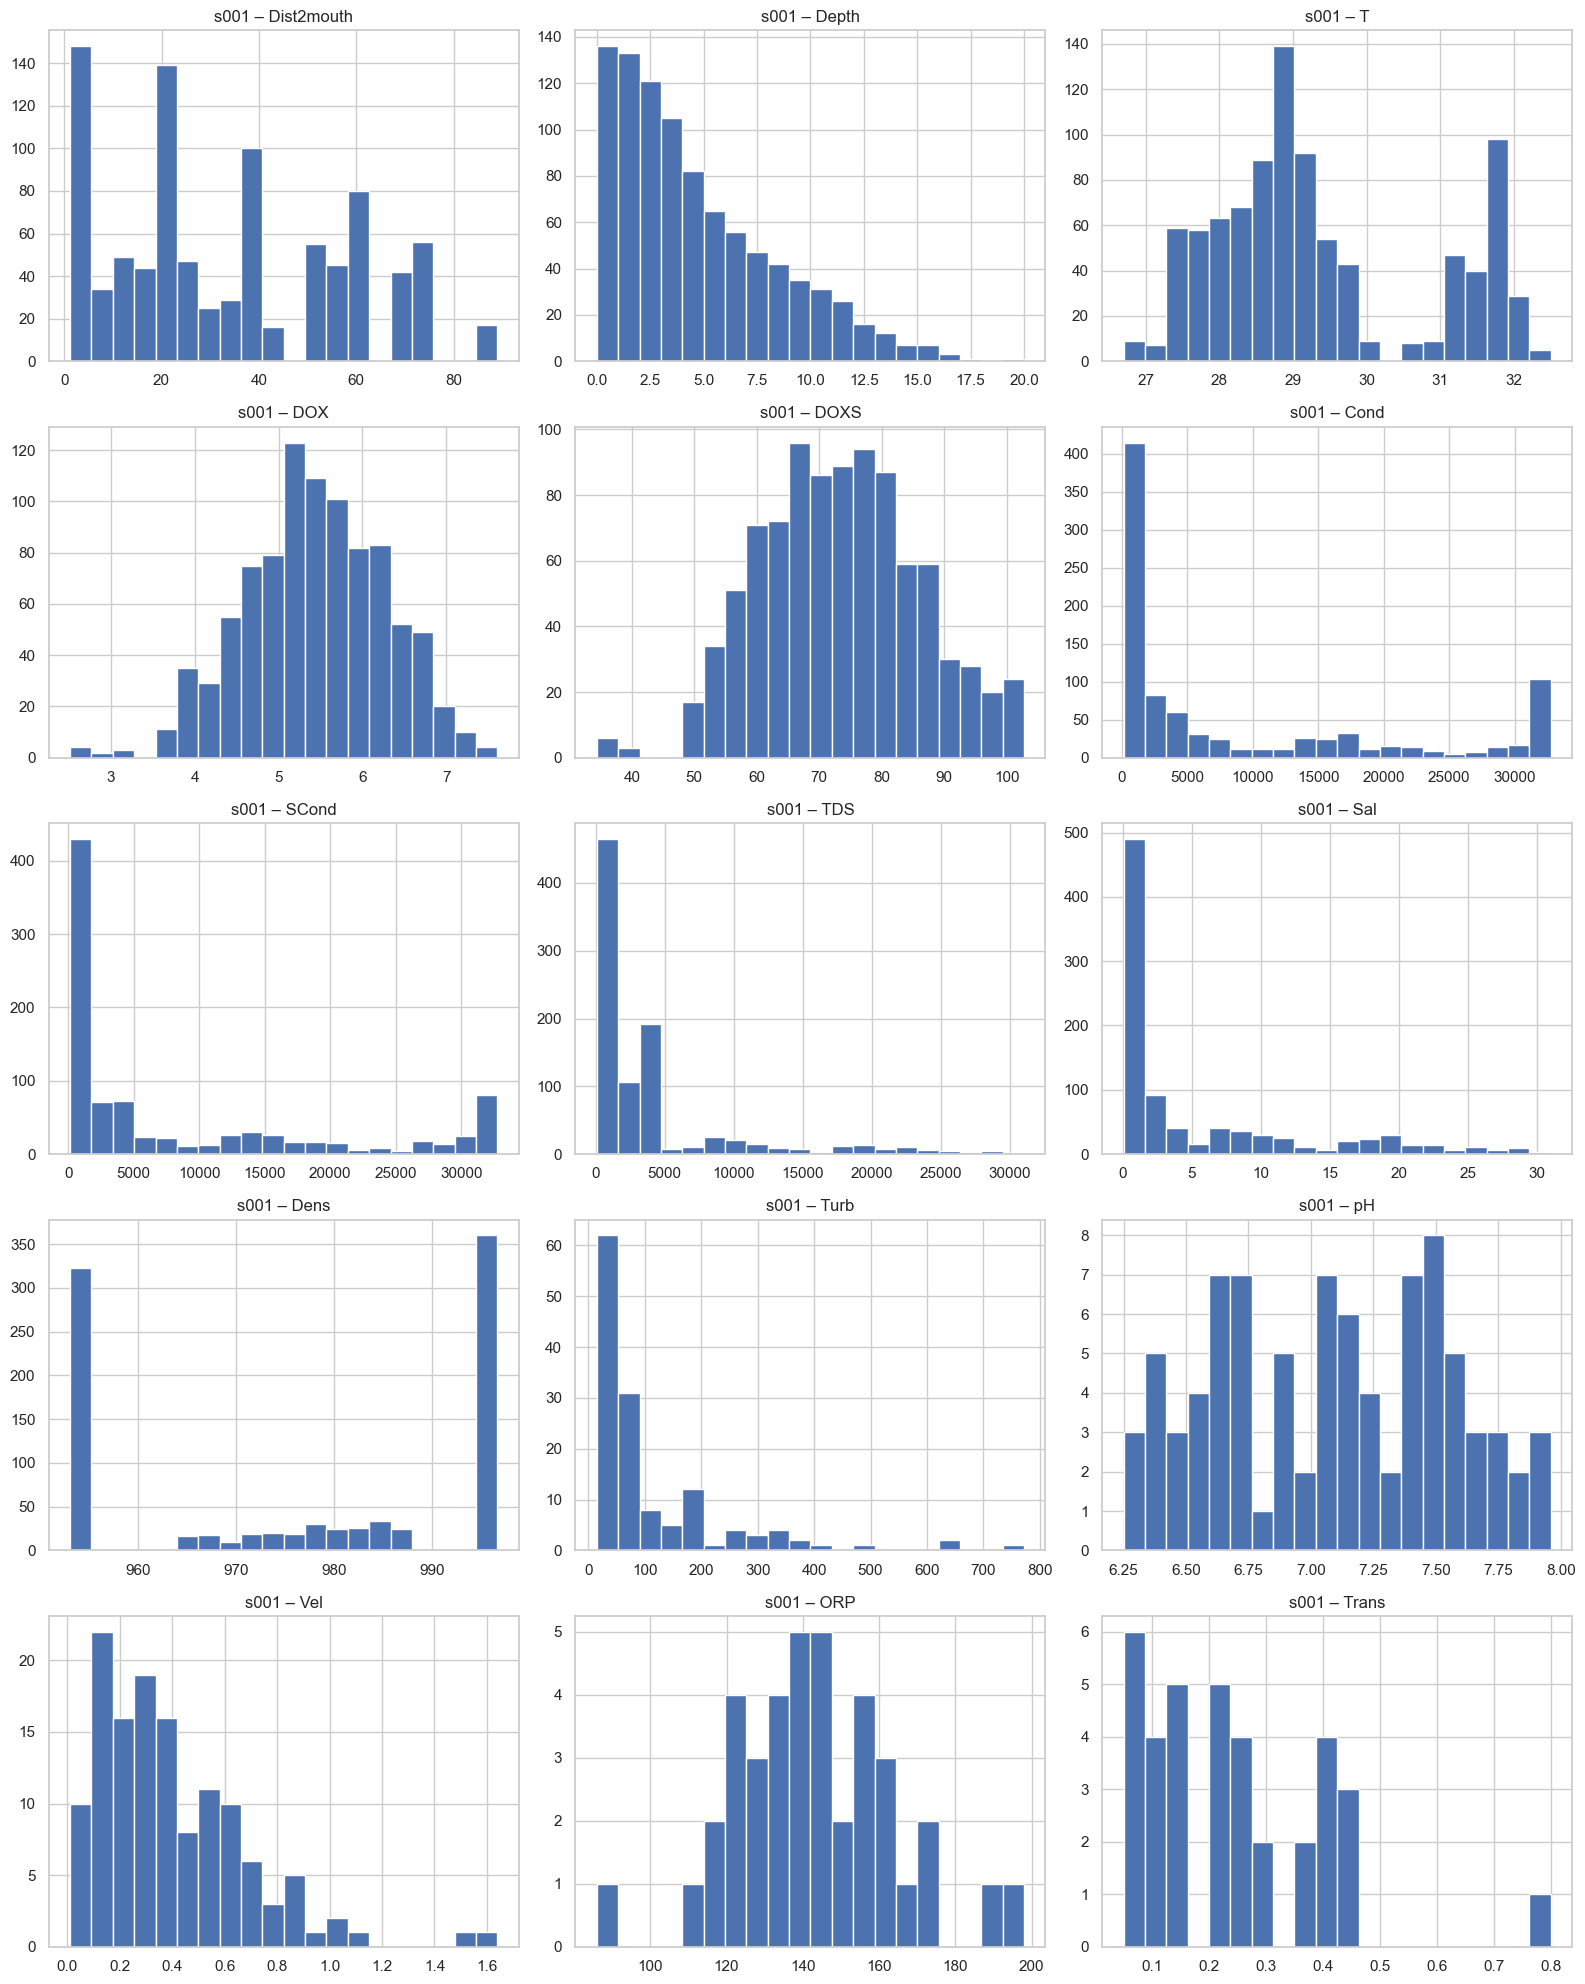

,count,mean,std,min,25%,50%,75%,max
SLatitude,535.0,10.188263,0.327907,9.459280,9.962792,10.233988,10.339865,10.854153
SLongitude,535.0,106.004202,0.482491,105.079500,105.563918,106.087807,106.427417,106.807220
ELatitude,535.0,10.184129,0.327612,9.476596,9.962075,10.229075,10.339329,10.853410
ELongitude,535.0,106.008832,0.478358,105.079250,105.576464,106.094241,106.420609,106.808784
Length,535.0,1528.669159,530.689955,206.000000,1122.500000,1500.000000,1860.000000,4395.000000
Depth,399.0,10.067669,5.325857,1.000000,6.000000,9.000000,13.000000,35.000000
TSpeed,478.0,78.671548,25.802159,12.000000,60.000000,81.000000,93.000000,327.000000
TDuration,500.0,19.470000,4.014141,3.000000,19.000000,20.000000,20.000000,53.000000
s.T,479.0,29.680167,1.418380,26.000000,28.700000,30.000000,30.700000,33.200000
b.T,380.0,29.587105,1.557048,26.000000,28.500000,30.000000,30.700000,34.100000


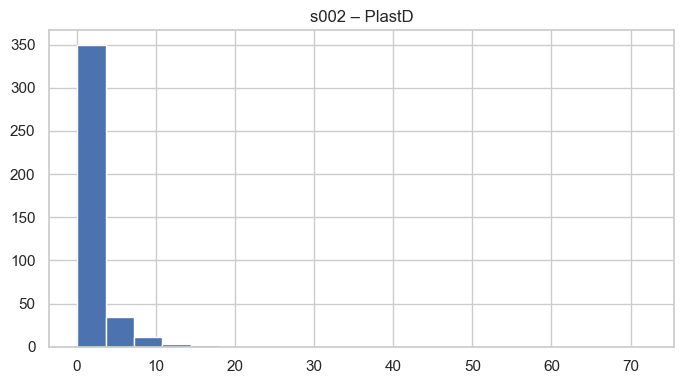

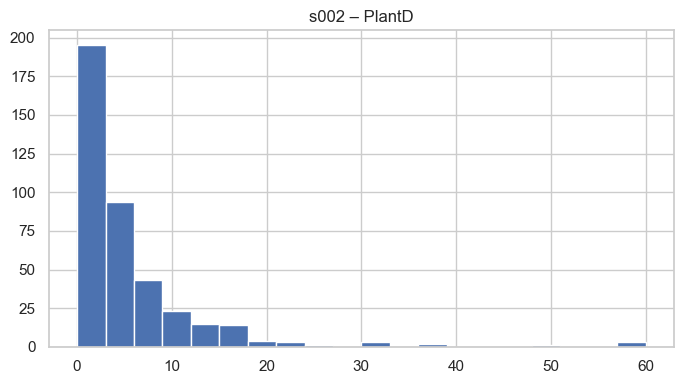

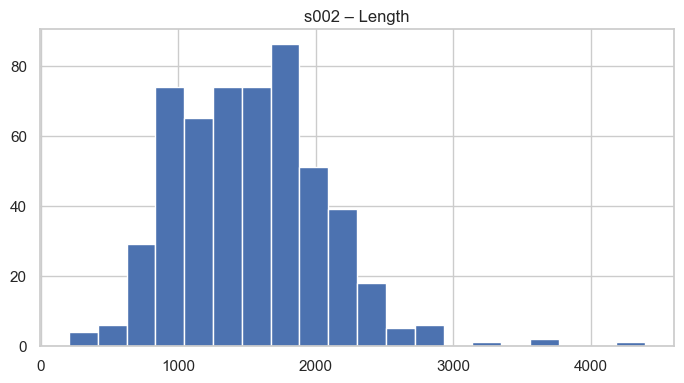

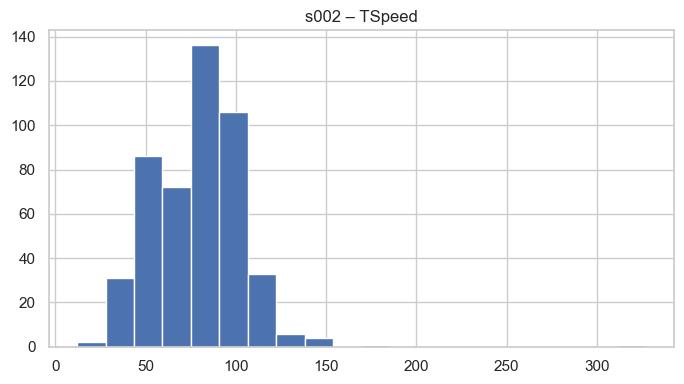

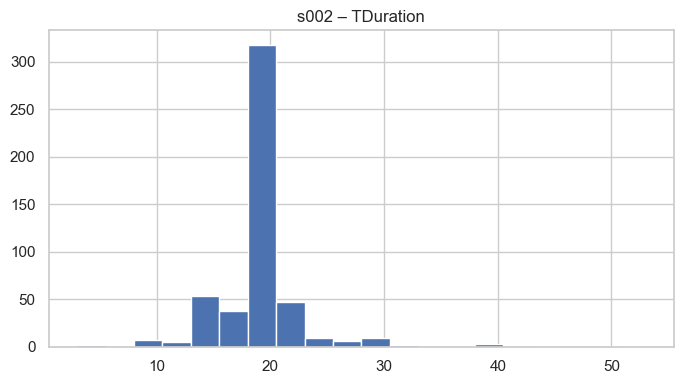

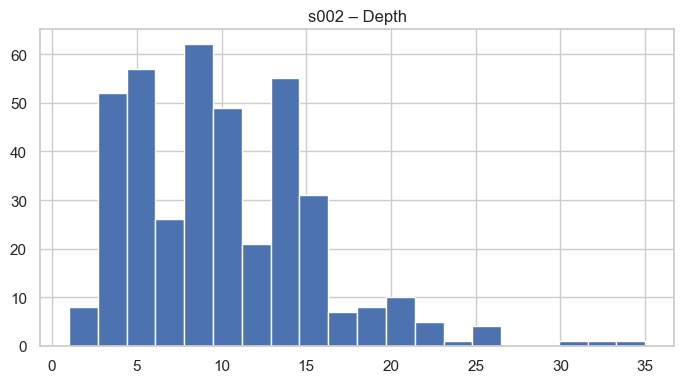

Số Taxa: 49


,count,sum,mean
Taxa,,,
Polynemidae,451,17696,39.237251
Pangasiidae,267,14305,53.576779
Engraulidae,330,12171,36.881818
Ariidae,332,11242,33.861446
Cynoglossidae,347,9460,27.262248
Cyprinidae,266,6655,25.018797
Sciaenidae,390,6017,15.428205
Akysidae,146,3830,26.232877
Soleidae,239,1273,5.326360


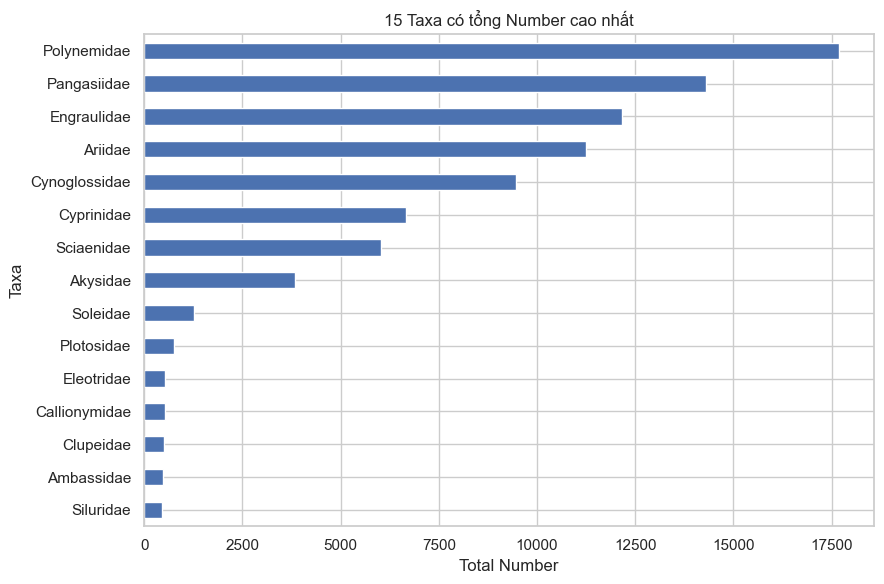

,count,mean,std,min,25%,50%,75%,max
Station,70.0,41.557143,26.174241,2.000,20.25000,37.500,64.0000,90.000
Depth,70.0,6.028571,4.215126,0.000,3.00000,4.500,9.0000,16.000
Sed1,70.0,4.041429,3.474023,0.200,1.22500,2.550,6.1750,12.200
Sed2,70.0,36.697143,14.312222,4.200,27.27500,37.400,44.4500,74.800
Sed3,70.0,30.334286,11.051577,8.300,23.02500,30.050,35.3750,72.800
Sed4,70.0,15.497143,7.251086,3.500,10.52500,14.750,18.5750,38.900
Sed5,70.0,8.037143,4.645433,0.700,4.70000,6.550,11.4750,20.300
Gravel,70.0,4.964286,11.431967,0.100,0.70000,1.400,2.3750,62.200
Sand,70.0,71.072857,14.787048,15.300,66.02500,73.550,79.4750,93.900
Clay,70.0,23.534286,10.045648,5.900,17.85000,22.750,29.1750,53.100


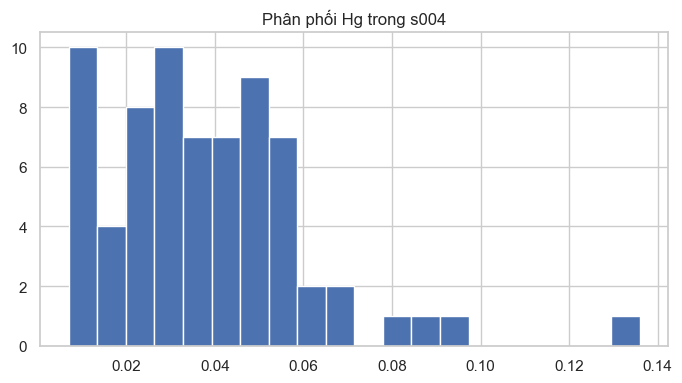

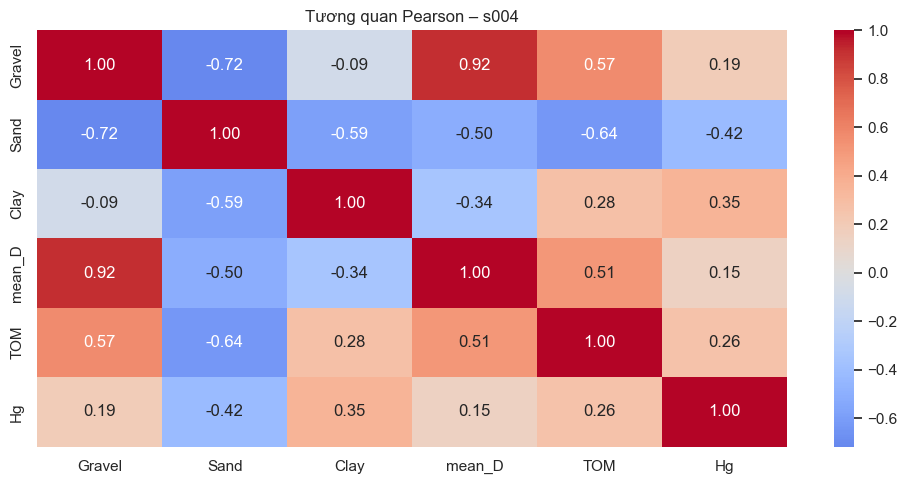

In [3]:
# EDA s001 – chất lượng nước: thống kê và phân phối biến số
water_numeric = df_water.select_dtypes(include=np.number)
water_features = [c for c in water_numeric.columns if c not in ["Station", "Latitude", "Longitude"]]
display(water_numeric.describe().T)
if water_features:
    ncols = 3
    nrows = int(np.ceil(len(water_features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4*nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, water_features):
        ax.hist(df_water[col].dropna(), bins=20)
        ax.set_title(f"s001 – {col}")
    for ax in axes[len(water_features):]: ax.axis("off")
    plt.tight_layout(); plt.show()

# EDA s002 – môi trường
numeric_env = df_environment.select_dtypes(include=np.number).columns.tolist()
display(df_environment[numeric_env].describe().T)
for col in ["PlastD", "PlantD", "Length", "TSpeed", "TDuration", "Depth"]:
    if col in df_environment.columns:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.hist(df_environment[col].dropna(), bins=20)
        ax.set_title(f"s002 – {col}"); plt.tight_layout(); plt.show()

# EDA s003 – sinh học
required_bio = {"Trawl", "Waterbody", "Datetime", "Depth", "Taxa", "Number"}
missing_required = required_bio - set(df_biology.columns)
if missing_required:
    raise ValueError(f"s003 thiếu cột bắt buộc: {sorted(missing_required)}")
df_biology["Number"] = pd.to_numeric(df_biology["Number"], errors="coerce")
print("Số Taxa:", df_biology["Taxa"].nunique())
display(df_biology.groupby("Taxa")["Number"].agg(["count", "sum", "mean"]).sort_values("sum", ascending=False).head(15))
top_taxa = df_biology.groupby("Taxa")["Number"].sum().nlargest(15).sort_values()
top_taxa.plot(kind="barh", figsize=(9, 6), title="15 Taxa có tổng Number cao nhất")
plt.xlabel("Total Number"); plt.tight_layout(); plt.show()

# EDA s004 – trầm tích và Hg
sediment_numeric = df_sediment.select_dtypes(include=np.number).columns.tolist()
display(df_sediment[sediment_numeric].describe().T)
if "Hg" in df_sediment.columns:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(df_sediment["Hg"].dropna(), bins=20)
    ax.set_title("Phân phối Hg trong s004"); plt.tight_layout(); plt.show()
    sediment_corr = [c for c in ["Gravel", "Sand", "Clay", "mean_D", "TOM", "Hg"] if c in df_sediment]
    if len(sediment_corr) >= 2:
        sns.heatmap(df_sediment[sediment_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
        plt.title("Tương quan Pearson – s004"); plt.tight_layout(); plt.show()

## CHƯƠNG 3. DATA INTEGRATION VÀ XÂY DỰNG ĐƠN VỊ MẪU

Khóa ghép s002–s003 gồm `Trawl`, `Waterbody`, `Datetime`. s002 là dữ liệu cấp chuyến kéo; s003 có nhiều dòng Taxa trong một mẫu. Trước khi ghép phải kiểm tra khóa trùng và số khóa khớp.

Một mẫu sinh học được định nghĩa theo `Trawl`, `Waterbody`, `Datetime`, `Depth`. Không dùng chỉ số dòng để ghép.

In [4]:
JOIN_KEYS = ["Trawl", "Waterbody", "Datetime"]
SAMPLE_KEYS = ["Trawl", "Waterbody", "Datetime", "Depth"]
for name, frame in [("s002", df_environment), ("s003", df_biology)]:
    absent = set(JOIN_KEYS) - set(frame.columns)
    if absent: raise ValueError(f"{name} thiếu khóa ghép: {absent}")
    print(name, "rows:", len(frame), "unique keys:", frame[JOIN_KEYS].drop_duplicates().shape[0],
          "rows with missing keys:", int(frame[JOIN_KEYS].isna().any(axis=1).sum()))

keys_env = df_environment[JOIN_KEYS].drop_duplicates()
keys_bio = df_biology[JOIN_KEYS].drop_duplicates()
key_check = keys_env.merge(keys_bio, on=JOIN_KEYS, how="outer", indicator=True)
display(key_check["_merge"].value_counts().rename_axis("Match status").to_frame("Unique keys"))
print("Khóa chỉ có trong s002:", int((key_check["_merge"] == "left_only").sum()))
print("Khóa chỉ có trong s003:", int((key_check["_merge"] == "right_only").sum()))

# Kiểm tra tính duy nhất của khóa s002. Nếu có khóa lặp, tổng hợp theo chuyến kéo.
env_for_join = df_environment.copy()
if env_for_join.duplicated(JOIN_KEYS).any():
    numeric_cols = env_for_join.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = [c for c in env_for_join.columns if c not in JOIN_KEYS + numeric_cols]
    agg = {c: "mean" for c in numeric_cols}
    agg.update({c: "first" for c in categorical_cols})
    env_for_join = env_for_join.groupby(JOIN_KEYS, dropna=False).agg(agg).reset_index()

bio_linked = df_biology.merge(env_for_join, on=JOIN_KEYS, how="left", validate="many_to_one",
                              indicator=True, suffixes=("_bio", "_env"))
print("Số bản ghi s003:", len(df_biology))
print("Số bản ghi sinh học ghép được môi trường:", int((bio_linked["_merge"] == "both").sum()))
print("Số khóa mẫu sinh học:", df_biology[SAMPLE_KEYS].drop_duplicates().shape[0])
display(bio_linked["_merge"].value_counts())

s002 rows: 535 unique keys: 535 rows with missing keys: 0
s003 rows: 4161 unique keys: 527 rows with missing keys: 0


,Unique keys
Match status,
both,527
left_only,8
right_only,0


Khóa chỉ có trong s002: 8
Khóa chỉ có trong s003: 0
Số bản ghi s003: 4161
Số bản ghi sinh học ghép được môi trường: 4161
Số khóa mẫu sinh học: 527


_merge
both          4161
left_only        0
right_only       0
Name: count, dtype: int64

In [5]:
# Tổng hợp s003 thành một dòng cho mỗi mẫu khảo sát
bio_work = df_biology.copy()
bio_work["Number"] = pd.to_numeric(bio_work["Number"], errors="coerce")
if "Biomass" in bio_work:
    bio_work["Biomass"] = pd.to_numeric(bio_work["Biomass"], errors="coerce")
else:
    bio_work["Biomass"] = np.nan
if (bio_work["Number"].dropna() < 0).any():
    raise ValueError("Number có giá trị âm; cần kiểm tra dữ liệu nguồn.")

sample_data = (bio_work.groupby(SAMPLE_KEYS, dropna=False)
    .agg(Taxa_Richness=("Taxa", "nunique"),
         Total_Number=("Number", lambda x: x.sum(min_count=1)),
         Total_Biomass=("Biomass", lambda x: x.sum(min_count=1)),
         Mean_Number=("Number", "mean"), Mean_Biomass=("Biomass", "mean"),
         Max_Number=("Number", "max"), Max_Biomass=("Biomass", "max"))
    .reset_index().rename(columns={"Depth": "Bio_Depth"}))
print("Số mẫu sinh học độc lập:", len(sample_data))
display(sample_data.head())

# Ma trận mẫu × Taxa; Number thiếu được bỏ khỏi phép cộng, không thay thành số 0.
valid_records = bio_work.dropna(subset=["Number", "Taxa"])
abundance_wide = valid_records.pivot_table(index=SAMPLE_KEYS, columns="Taxa",
                                            values="Number", aggfunc="sum", fill_value=0)
abundance_wide.columns = abundance_wide.columns.astype(str)
abundance_wide.columns.name = None
sample_index_for_matrix = sample_data.set_index(["Trawl", "Waterbody", "Datetime", "Bio_Depth"]).rename_axis(SAMPLE_KEYS).index
abundance_wide = abundance_wide.reindex(sample_index_for_matrix, fill_value=0).reset_index()
print("Ma trận abundance:", abundance_wide.shape)
display(abundance_wide.iloc[:5, :10])

Số mẫu sinh học độc lập: 527


,Trawl,Waterbody,Datetime,Bio_Depth,Taxa_Richness,Total_Number,Total_Biomass,Mean_Number,Mean_Biomass,Max_Number,Max_Biomass
0,BL-423,Tien (Branch Ba Lai),2020-05-31T08:45,0,6,138,1057.09,23.000000,176.181667,89,594.00
1,BL-424,Tien (Branch Ba Lai),2020-05-31T09:16,0,4,103,344.03,25.750000,86.007500,73,175.66
2,BL-425,Tien (Branch Ba Lai),2020-05-31T09:55,0,11,133,1417.30,12.090909,128.845455,48,456.00
3,BL-427,Tien (Branch Ba Lai),2020-05-31T11:25,0,12,66,1379.14,5.500000,114.928333,23,1125.00
4,BL-428,Tien (Branch Ba Lai),2020-06-01T08:20,0,6,33,439.00,5.500000,73.166667,11,281.36


Ma trận abundance: (527, 53)


,Trawl,Waterbody,Datetime,Depth,Akysidae,Ambassidae,Ariidae,Bagridae,Batrachoididae,Botiidae
0,BL-423,Tien (Branch Ba Lai),2020-05-31T08:45,0,0,0,0,0,0,0
1,BL-424,Tien (Branch Ba Lai),2020-05-31T09:16,0,0,0,0,0,0,0
2,BL-425,Tien (Branch Ba Lai),2020-05-31T09:55,0,0,0,10,0,0,0
3,BL-427,Tien (Branch Ba Lai),2020-05-31T11:25,0,0,0,23,0,0,0
4,BL-428,Tien (Branch Ba Lai),2020-06-01T08:20,0,0,0,6,0,0,0


In [6]:
# Kiểm tra tính nhất quán tổng Number và Taxa richness
pivot_check = abundance_wide.copy()
taxa_columns = [c for c in pivot_check.columns if c not in SAMPLE_KEYS]
pivot_check["Pivot_Total_Number"] = pivot_check[taxa_columns].sum(axis=1)
pivot_check["Pivot_Richness"] = (pivot_check[taxa_columns] > 0).sum(axis=1)
check_table = pivot_check.merge(
    sample_data, left_on=SAMPLE_KEYS,
    right_on=["Trawl", "Waterbody", "Datetime", "Bio_Depth"],
    how="left", validate="one_to_one")
check_table["Number_difference"] = (check_table["Pivot_Total_Number"] - check_table["Total_Number"]).abs()
check_table["Richness_difference"] = (check_table["Pivot_Richness"] - check_table["Taxa_Richness"]).abs()
print("Sai khác tổng Number lớn nhất:", check_table["Number_difference"].max())
print("Sai khác Taxa richness lớn nhất:", check_table["Richness_difference"].max())
display(check_table.head())

Sai khác tổng Number lớn nhất: 0
Sai khác Taxa richness lớn nhất: 0


,Trawl,Waterbody,Datetime,Depth,Akysidae,Ambassidae,Ariidae,Bagridae,Batrachoididae,Botiidae,Bregmacerotidae,Callionymidae,Carangidae,Cichlidae,Clariidae,Clupeidae,Cobitidae,Cynoglossidae,Cyprinidae,Dasyatidae,Drepaneidae,Eleotridae,Engraulidae,Gerreidae,Gobiidae,Leiognathidae,Lobotidae,Loricariidae,Mastacembelidae,Megalopidae,Mugilidae,Muraenesocidae,Ophichthidae,Pangasiidae,Platycephalidae,Plotosidae,Polynemidae,Pristigasteridae,Scatophagidae,Sciaenidae,Scombridae,Scorpaenidae,Siganidae,Sillaginidae,Siluridae,Sisoridae,Soleidae,Sphyraenidae,Stromateidae,Synodontidae,Tetraodontidae,Toxotidae,Trichiuridae,Pivot_Total_Number,Pivot_Richness,Bio_Depth,Taxa_Richness,Total_Number,Total_Biomass,Mean_Number,Mean_Biomass,Max_Number,Max_Biomass,Number_difference,Richness_difference
0,BL-423,Tien (Branch Ba Lai),2020-05-31T08:45,0,0,0,0,0,0,0,0,0,0,0,0,0,0,7,0,0,0,1,0,0,22,0,0,0,0,0,0,0,0,0,0,18,1,0,0,89,0,0,0,0,0,0,0,0,0,0,0,0,0,138,6,0,6,138,1057.09,23.000000,176.181667,89,594.00,0,0
1,BL-424,Tien (Branch Ba Lai),2020-05-31T09:16,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8,0,0,0,0,0,0,0,0,0,0,20,2,0,0,73,0,0,0,0,0,0,0,0,0,0,0,0,0,103,4,0,4,103,344.03,25.750000,86.007500,73,175.66,0,0
2,BL-425,Tien (Branch Ba Lai),2020-05-31T09:55,0,0,0,10,0,0,0,0,0,0,0,0,0,0,3,0,0,0,4,3,1,24,0,2,0,0,0,0,0,0,0,0,20,0,0,12,48,0,0,0,6,0,0,0,0,0,0,0,0,0,133,11,0,11,133,1417.30,12.090909,128.845455,48,456.00,0,0
3,BL-427,Tien (Branch Ba Lai),2020-05-31T11:25,0,0,0,23,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,4,0,8,13,1,0,0,0,0,0,0,0,2,2,0,0,1,8,0,1,0,2,0,0,0,0,0,0,0,0,0,66,12,0,12,66,1379.14,5.500000,114.928333,23,1125.00,0,0
4,BL-428,Tien (Branch Ba Lai),2020-06-01T08:20,0,0,0,6,0,0,0,0,0,0,0,0,0,0,0,3,0,0,0,0,0,7,0,0,0,0,0,0,0,0,0,0,11,0,0,0,4,0,0,0,0,0,0,2,0,0,0,0,0,0,33,6,0,6,33,439.00,5.500000,73.166667,11,281.36,0,0


## CHƯƠNG 4. PREPROCESSING VÀ BIỂU DIỄN DỮ LIỆU

Ta so sánh ba cách biểu diễn trên cùng tập mẫu hợp lệ:

1. **Raw abundance:** số lượng cá thể ghi nhận. Có thể chịu ảnh hưởng bởi tổng số cá thể của từng mẫu.
2. **Relative abundance:** chia abundance từng Taxa cho tổng abundance của mẫu.
3. **Hellinger:** lấy căn bậc hai của relative abundance. Phù hợp khi muốn so sánh thành phần tương đối của quần xã.

Mẫu có tổng abundance bằng 0 không thể chuẩn hóa theo tổng mẫu nên được loại khỏi phân cụm và được thống kê riêng. Number thiếu không được mặc định là 0; các dòng thiếu Number không tham gia ma trận abundance. Ô 0 trong ma trận pivot biểu thị không có bản ghi Taxa đó trong mẫu, giả định này cần được xác nhận bằng metadata nguồn.

In [7]:
X_abundance_all = abundance_wide.set_index(SAMPLE_KEYS)[taxa_columns].apply(pd.to_numeric, errors="coerce").fillna(0).clip(lower=0)
row_totals = X_abundance_all.sum(axis=1)
valid_mask = row_totals > 0
invalid_samples = X_abundance_all.loc[~valid_mask]
X_abundance = X_abundance_all.loc[valid_mask].copy()
X_relative = X_abundance.div(X_abundance.sum(axis=1), axis=0)
X_hellinger = np.sqrt(X_relative)

print("Tổng số mẫu:", len(X_abundance_all))
print("Mẫu hợp lệ đưa vào phân cụm:", len(X_abundance))
print("Mẫu tổng abundance bằng 0:", int((~valid_mask).sum()))
print("Số Taxa:", X_abundance.shape[1])
display(X_relative.head().round(3))

Tổng số mẫu: 527
Mẫu hợp lệ đưa vào phân cụm: 527
Mẫu tổng abundance bằng 0: 0
Số Taxa: 49


,,,,Akysidae,Ambassidae,Ariidae,Bagridae,Batrachoididae,Botiidae,Bregmacerotidae,Callionymidae,Carangidae,Cichlidae,Clariidae,Clupeidae,Cobitidae,Cynoglossidae,Cyprinidae,Dasyatidae,Drepaneidae,Eleotridae,Engraulidae,Gerreidae,Gobiidae,Leiognathidae,Lobotidae,Loricariidae,Mastacembelidae,Megalopidae,Mugilidae,Muraenesocidae,Ophichthidae,Pangasiidae,Platycephalidae,Plotosidae,Polynemidae,Pristigasteridae,Scatophagidae,Sciaenidae,Scombridae,Scorpaenidae,Siganidae,Sillaginidae,Siluridae,Sisoridae,Soleidae,Sphyraenidae,Stromateidae,Synodontidae,Tetraodontidae,Toxotidae,Trichiuridae
Trawl,Waterbody,Datetime,Depth,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
BL-423,Tien (Branch Ba Lai),2020-05-31T08:45,0,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.051,0.000,0.0,0.0,0.007,0.000,0.000,0.159,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.130,0.007,0.0,0.000,0.645,0.0,0.000,0.0,0.000,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0
BL-424,Tien (Branch Ba Lai),2020-05-31T09:16,0,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.000,0.000,0.078,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.194,0.019,0.0,0.000,0.709,0.0,0.000,0.0,0.000,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0
BL-425,Tien (Branch Ba Lai),2020-05-31T09:55,0,0.0,0.0,0.075,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.023,0.000,0.0,0.0,0.030,0.023,0.008,0.180,0.000,0.015,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.150,0.000,0.0,0.090,0.361,0.0,0.000,0.0,0.045,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0
BL-427,Tien (Branch Ba Lai),2020-05-31T11:25,0,0.0,0.0,0.348,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.015,0.000,0.0,0.0,0.000,0.061,0.000,0.121,0.197,0.015,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.03,0.030,0.000,0.0,0.015,0.121,0.0,0.015,0.0,0.030,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0
BL-428,Tien (Branch Ba Lai),2020-06-01T08:20,0,0.0,0.0,0.182,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.091,0.0,0.0,0.000,0.000,0.000,0.212,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.333,0.000,0.0,0.000,0.121,0.0,0.000,0.0,0.000,0.0,0.0,0.061,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
# Lọc Taxa hiếm để làm phân tích độ nhạy (không thay thế kết quả chính)
taxa_prevalence = (X_abundance > 0).mean(axis=0)
rare_threshold = 0.02
kept_taxa = taxa_prevalence[taxa_prevalence >= rare_threshold].index
X_relative_filtered = X_abundance[kept_taxa].div(X_abundance[kept_taxa].sum(axis=1), axis=0)
X_hellinger_filtered = np.sqrt(X_relative_filtered)
prevalence_summary = pd.DataFrame({
    "Ngưỡng xuất hiện": [0.01, 0.02, 0.05],
    "Số Taxa giữ lại": [(taxa_prevalence >= t).sum() for t in [0.01, 0.02, 0.05]],
    "Số Taxa loại": [(taxa_prevalence < t).sum() for t in [0.01, 0.02, 0.05]]
})
display(prevalence_summary)
print(f"Ngưỡng 2%: giữ {len(kept_taxa)} / {X_abundance.shape[1]} Taxa")

,Ngưỡng xuất hiện,Số Taxa giữ lại,Số Taxa loại
0,0.01,36,13
1,0.02,30,19
2,0.05,20,29


Ngưỡng 2%: giữ 30 / 49 Taxa


## CHƯƠNG 5. K-MEANS VÀ ĐÁNH GIÁ MÔ HÌNH

K-Means chia mẫu thành K cụm bằng cách tối thiểu hóa tổng bình phương khoảng cách từ mỗi điểm đến tâm cụm gần nhất. Đây là thuật toán phân cụm cơ bản, dễ triển khai và phù hợp phạm vi đồ án.

Chọn K bằng cách khảo sát Elbow (Inertia) và Silhouette trong khoảng 2–10. Silhouette càng cao thường thể hiện cụm tách biệt tốt hơn; Davies–Bouldin càng thấp càng tốt; Calinski–Harabasz càng cao càng tốt. Không có một chỉ số đơn lẻ nào chứng minh ý nghĩa sinh thái của cụm.

d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

,Biểu diễn,K tốt nhất,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,Raw abundance,2,0.9416,0.4362,505.3065
1,Relative abundance,7,0.3783,0.9962,205.5857
2,Hellinger,2,0.2597,1.5931,196.1747
3,Hellinger + lọc Taxa hiếm,2,0.2615,1.5854,198.1968


d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Inertia
0,2,0.2597,1.5931,196.1747,217.9412
1,3,0.1989,1.7352,142.5778,193.8741
2,4,0.1986,1.7566,132.2368,170.2438
3,5,0.2095,1.6156,124.0516,153.4813
4,6,0.2127,1.5094,119.4379,139.4900
5,7,0.2250,1.4451,118.1261,126.6946
6,8,0.2073,1.5902,107.0057,122.5336
7,9,0.1777,1.7220,98.4078,118.8098
8,10,0.1812,1.7544,91.3926,115.5467


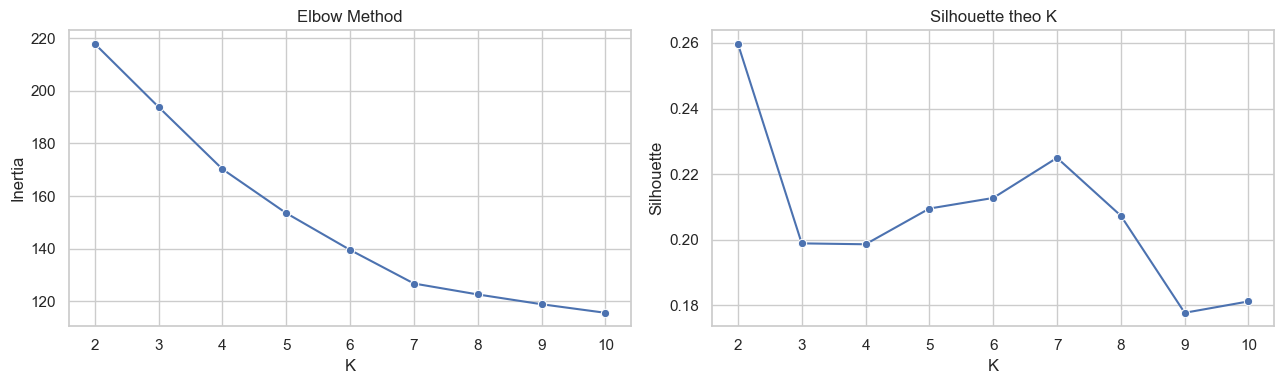

K được chọn: 2


d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


,Model,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Inertia,Feature_space
0,K-Means,2,0.2597,1.5931,196.1747,217.9412,Euclidean on Hellinger


In [9]:
def evaluate_kmeans(matrix, k, random_state=RANDOM_STATE, n_init=30):
    model = KMeans(n_clusters=int(k), random_state=random_state, n_init=n_init)
    labels = model.fit_predict(matrix)
    if len(np.unique(labels)) < 2 or len(np.unique(labels)) >= len(matrix):
        return None
    return {
        "model": model, "labels": labels,
        "Silhouette": silhouette_score(matrix, labels),
        "Davies_Bouldin": davies_bouldin_score(matrix, labels),
        "Calinski_Harabasz": calinski_harabasz_score(matrix, labels),
        "Inertia": model.inertia_
    }

def search_k(matrix, max_k=10):
    upper = min(max_k, len(matrix)-1)
    rows = []
    for k in range(2, upper+1):
        result = evaluate_kmeans(matrix, k)
        if result:
            rows.append({"K": k, **{m: result[m] for m in ["Silhouette", "Davies_Bouldin", "Calinski_Harabasz", "Inertia"]}})
    return pd.DataFrame(rows)

representation_matrices = {
    "Raw abundance": X_abundance,
    "Relative abundance": X_relative,
    "Hellinger": X_hellinger,
    "Hellinger + lọc Taxa hiếm": X_hellinger_filtered
}
comparison_rows = []
for name, matrix in representation_matrices.items():
    result_k = search_k(matrix, max_k=10)
    if not result_k.empty:
        best = result_k.loc[result_k["Silhouette"].idxmax()]
        comparison_rows.append({"Biểu diễn": name, "K tốt nhất": int(best["K"]),
                                "Silhouette": best["Silhouette"],
                                "Davies_Bouldin": best["Davies_Bouldin"],
                                "Calinski_Harabasz": best["Calinski_Harabasz"]})
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(4))

# Phân tích chính sử dụng Hellinger trên toàn bộ Taxa; bảng so sánh ở trên là bằng chứng lựa chọn.
k_search = search_k(X_hellinger, max_k=10)
if k_search.empty:
    raise ValueError("Không đủ mẫu để khảo sát K-Means.")
display(k_search.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=k_search, x="K", y="Inertia", marker="o", ax=axes[0]); axes[0].set_title("Elbow Method")
sns.lineplot(data=k_search, x="K", y="Silhouette", marker="o", ax=axes[1]); axes[1].set_title("Silhouette theo K")
plt.tight_layout(); plt.show()

best_k = int(k_search.loc[k_search["Silhouette"].idxmax(), "K"])
final_result = evaluate_kmeans(X_hellinger, best_k, n_init=50)
kmeans_model = final_result["model"]
kmeans_labels = final_result["labels"]
evaluation_table = pd.DataFrame([{"Model": "K-Means", "K": best_k,
    **{m: final_result[m] for m in ["Silhouette", "Davies_Bouldin", "Calinski_Harabasz", "Inertia"]},
    "Feature_space": "Euclidean on Hellinger"}])
print("K được chọn:", best_k)
display(evaluation_table.round(4))

### Độ ổn định cơ bản của kết quả

K-Means có thể thay đổi do khởi tạo tâm cụm. Ta chạy lại cùng K với một số random seed và so sánh nhãn bằng Adjusted Rand Index (ARI). ARI gần 1 biểu thị hai lần phân cụm nhất quán cao. Đây là kiểm tra độ ổn định cơ bản, không phải thuật toán phân cụm mới.

In [10]:
seed_results = []
reference_labels = kmeans_labels
for seed in [0, 1, 7, 21, 42, 99]:
    repeated = evaluate_kmeans(X_hellinger, best_k, random_state=seed, n_init=30)
    seed_results.append({"Random seed": seed,
                         "Silhouette": repeated["Silhouette"],
                         "ARI so với seed 42": adjusted_rand_score(reference_labels, repeated["labels"])})
stability_table = pd.DataFrame(seed_results)
display(stability_table.round(4))
print("ARI trung bình (không tính lần tham chiếu):",
      round(stability_table.loc[stability_table["Random seed"] != 42, "ARI so với seed 42"].mean(), 4))

d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\ANaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

,Random seed,Silhouette,ARI so với seed 42
0,0,0.2597,1.0
1,1,0.2597,1.0
2,7,0.2597,1.0
3,21,0.2597,1.0
4,42,0.2597,1.0
5,99,0.2597,1.0


ARI trung bình (không tính lần tham chiếu): 1.0


## CHƯƠNG 6. TRỰC QUAN HÓA VÀ DIỄN GIẢI CỤM

PCA được dùng để biểu diễn dữ liệu nhiều chiều trên mặt phẳng hai chiều. PCA không tham gia tạo nhãn cụm; nhãn được tạo bằng K-Means trên ma trận Hellinger.

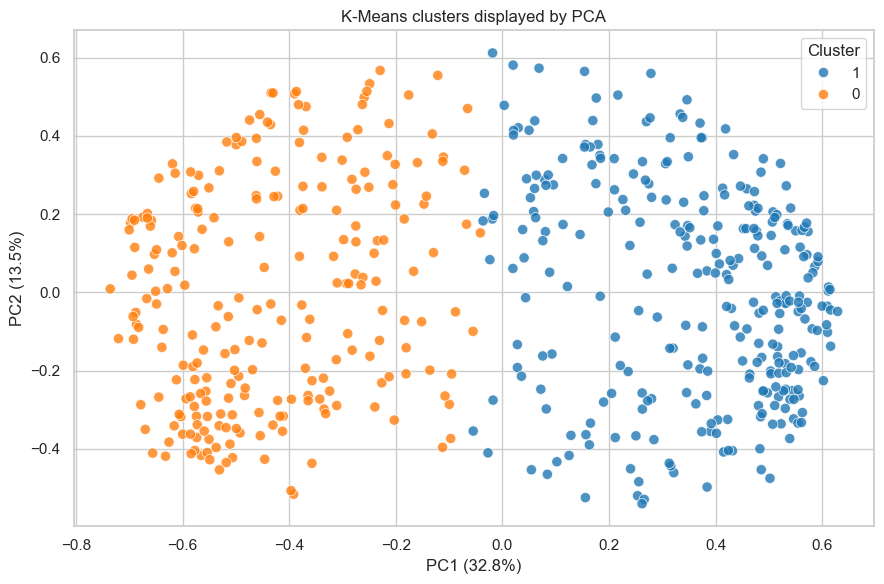

Tổng phương sai giải thích bởi hai PC: 46.32 %


,Number of samples
Cluster,
0,238
1,289


Taxa_Richness              Total_Number                Total_Biomass  \
                 mean median   std         mean median     std          mean   
Cluster                                                                        
0                8.59    9.0  2.46       173.53   95.0  327.65        885.19   
1                7.33    7.0  2.24       160.72  102.0  195.98       1056.60   

                        Mean_Number               Mean_Biomass                  
         median     std        mean median    std         mean  median     std  
Cluster                                                                         
0        633.24  794.59       19.02  10.62  32.66       100.77   80.20   81.97  
1        776.99  970.65       21.87  13.71  24.38       147.06  110.59  129.91


Cluster 0 – 10 Taxa có abundance tương đối trung bình cao


,Mean relative abundance
Cynoglossidae,0.222365
Pangasiidae,0.219914
Cyprinidae,0.209564
Polynemidae,0.104982
Sciaenidae,0.043195
Akysidae,0.036409
Soleidae,0.029280
Eleotridae,0.021227
Ariidae,0.018498
Bagridae,0.013828



Cluster 1 – 10 Taxa có abundance tương đối trung bình cao


,Mean relative abundance
Engraulidae,0.244147
Ariidae,0.227170
Polynemidae,0.217490
Sciaenidae,0.150224
Cynoglossidae,0.025061
Plotosidae,0.024878
Gobiidae,0.016249
Pangasiidae,0.012393
Cyprinidae,0.011227
Soleidae,0.010783


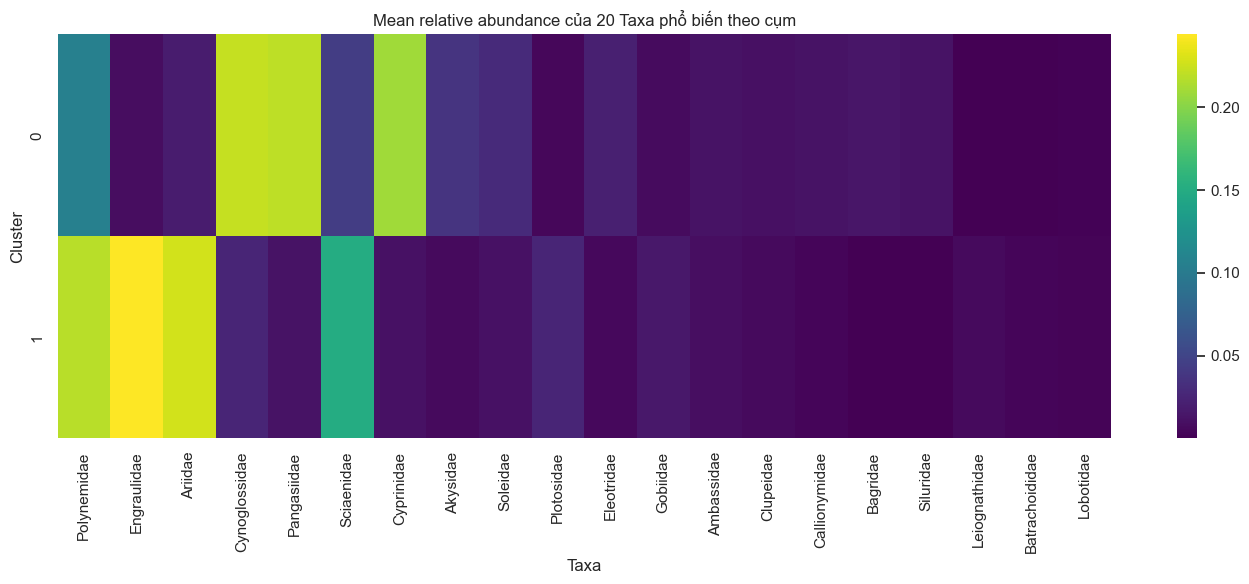

In [11]:
# Tạo bảng mẫu có đúng thứ tự hàng như ma trận Hellinger
sample_indexed = sample_data.set_index(["Trawl", "Waterbody", "Datetime", "Bio_Depth"]).rename_axis(SAMPLE_KEYS)
valid_sample_meta = sample_indexed.loc[X_hellinger.index].reset_index()
clustered_samples = valid_sample_meta.copy()
clustered_samples["Cluster"] = kmeans_labels

pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_hellinger)
pca_plot = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "Cluster": kmeans_labels.astype(str)})
plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_plot, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=55, alpha=.8)
plt.title("K-Means clusters displayed by PCA")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.tight_layout(); plt.show()
print("Tổng phương sai giải thích bởi hai PC:", round(pca.explained_variance_ratio_.sum()*100, 2), "%")

cluster_sizes = clustered_samples["Cluster"].value_counts().sort_index()
display(cluster_sizes.rename("Number of samples").to_frame())
profile_cols = [c for c in ["Taxa_Richness", "Total_Number", "Total_Biomass", "Mean_Number", "Mean_Biomass"] if c in clustered_samples]
cluster_profile = clustered_samples.groupby("Cluster")[profile_cols].agg(["mean", "median", "std"]).round(2)
display(cluster_profile)

community_with_cluster = X_relative.copy()
community_with_cluster["Cluster"] = kmeans_labels
cluster_taxa_mean = community_with_cluster.groupby("Cluster").mean()
for cluster_id in cluster_taxa_mean.index:
    print(f"\nCluster {cluster_id} – 10 Taxa có abundance tương đối trung bình cao")
    display(cluster_taxa_mean.loc[cluster_id].sort_values(ascending=False).head(10).rename("Mean relative abundance").to_frame())

top_taxa_overall = X_relative.mean().sort_values(ascending=False).head(20).index
plt.figure(figsize=(14, 6))
sns.heatmap(cluster_taxa_mean[top_taxa_overall], cmap="viridis")
plt.title("Mean relative abundance của 20 Taxa phổ biến theo cụm")
plt.xlabel("Taxa"); plt.ylabel("Cluster"); plt.tight_layout(); plt.show()

## CHƯƠNG 7. PHÂN TÍCH MÔI TRƯỜNG HẬU NGHIỆM

Ghép nhãn cụm vào s002 theo khóa `Trawl`, `Waterbody`, `Datetime`. Nếu s002 có nhiều dòng cùng khóa, tổng hợp biến số bằng trung bình và biến phân loại bằng giá trị đầu tiên trước khi ghép.

Với hai cụm, sử dụng Mann–Whitney U để so sánh phân phối giữa hai nhóm. Đây là kiểm định phi tham số cơ bản. Vì kiểm định nhiều biến, hiệu chỉnh p-value theo Benjamini–Hochberg để hạn chế phát hiện dương tính giả. Kết quả chỉ phản ánh khác biệt thống kê trong dữ liệu quan sát, không chứng minh nhân quả.

Số mẫu sau ghép: 527
Số mẫu có thông tin môi trường: 527


,Variable,Cluster,N,Mean,Median
0,Depth_env,0,204,10.921569,11.000
1,Depth_env,1,194,9.087629,8.000
2,Length,0,238,1480.596639,1495.000
3,Length,1,289,1561.882353,1499.000
4,TSpeed,0,214,76.766355,80.000
5,TSpeed,1,256,79.968750,81.500
6,TDuration,0,236,19.216102,20.000
7,TDuration,1,256,19.687500,20.000
8,s.T,0,208,29.825000,30.100
9,s.T,1,263,29.530038,29.800


,Variable,N_Cluster_0,Median_Cluster_0,N_Cluster_1,Median_Cluster_1,p_value,p_adjusted_BH
7,b.S,204,0.08,249,4.000,0.0000,0.0000
6,s.S,212,0.08,279,2.060,0.0000,0.0000
0,Depth_env,204,11.00,194,8.000,0.0000,0.0002
8,s.DOX,82,4.27,127,5.450,0.0001,0.0004
5,b.T,198,30.20,174,29.300,0.0005,0.0014
13,PlantD,226,2.65,167,3.700,0.0072,0.0167
4,s.T,208,30.10,263,29.800,0.0109,0.0217
2,TSpeed,214,80.00,256,81.500,0.0794,0.1389
1,Length,238,1495.00,289,1499.000,0.1600,0.2488
3,TDuration,236,20.00,256,20.000,0.5882,0.7283


Biến môi trường đạt ngưỡng quan sát 60%: ['Depth_env', 'Length', 'TSpeed', 'TDuration', 's.T', 'b.T', 's.S', 'b.S', 'PlastD', 'PlantD']


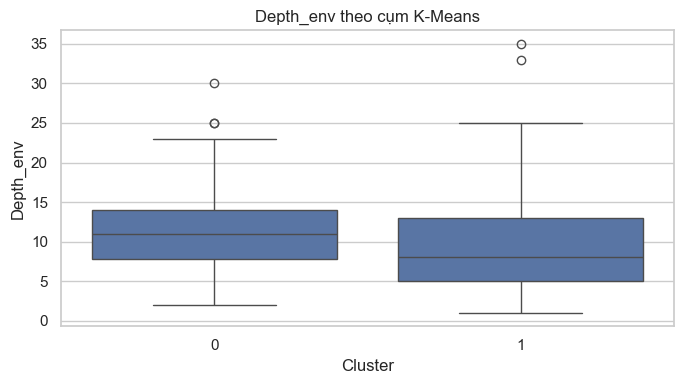

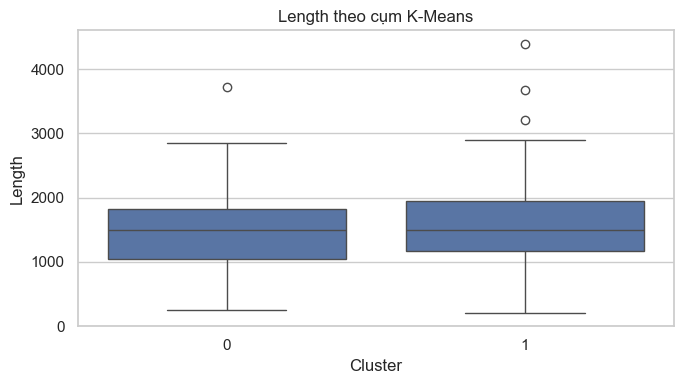

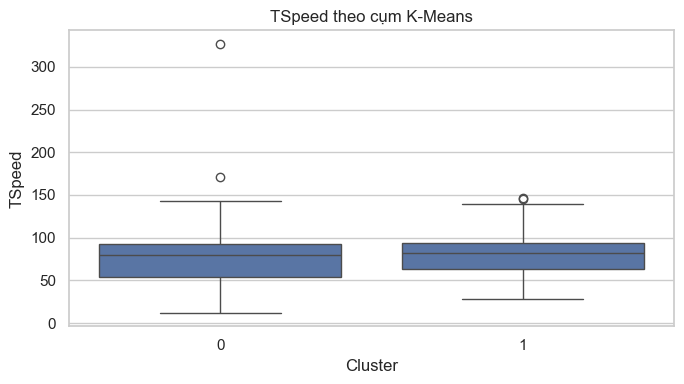

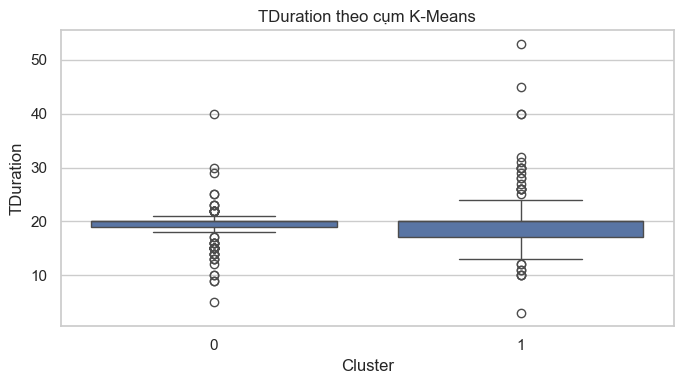

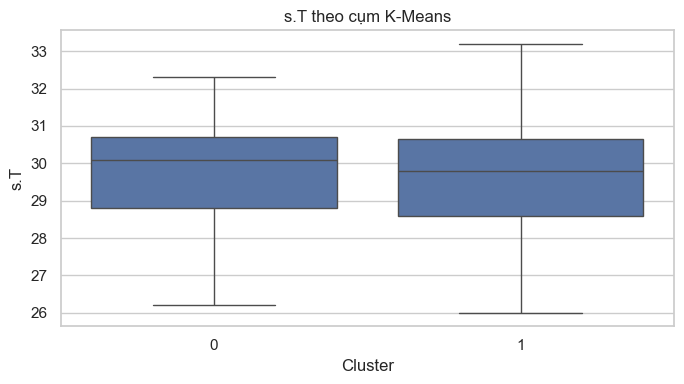

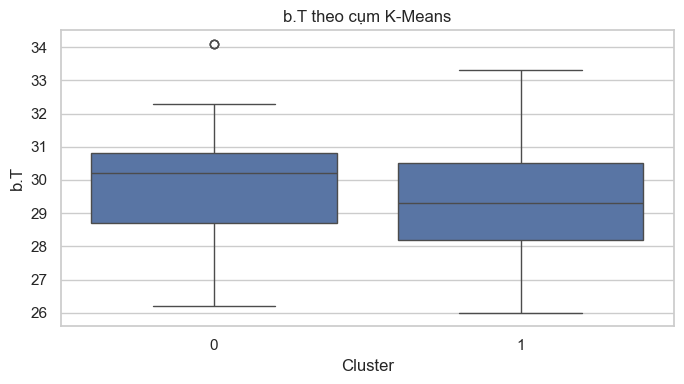

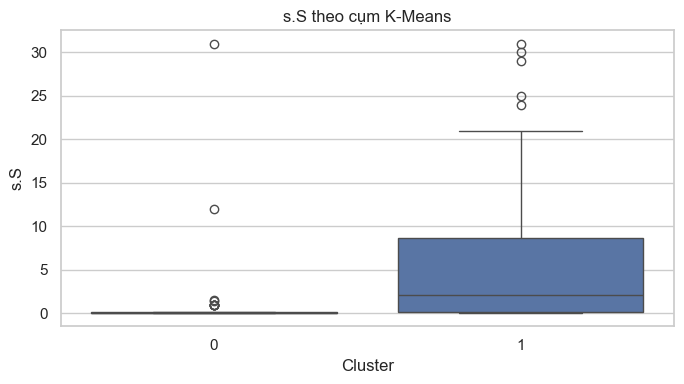

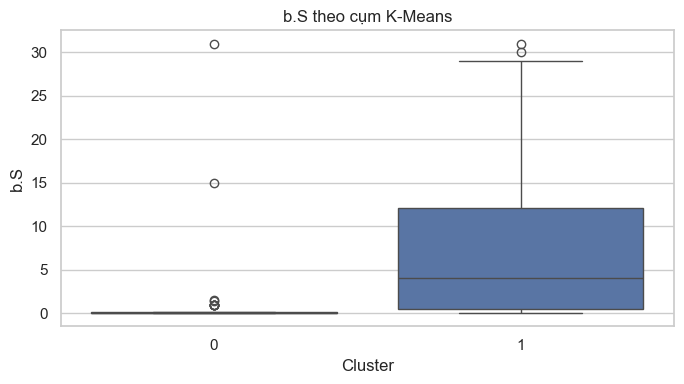

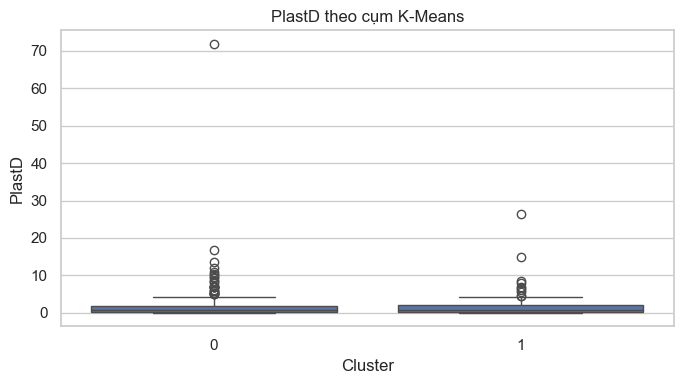

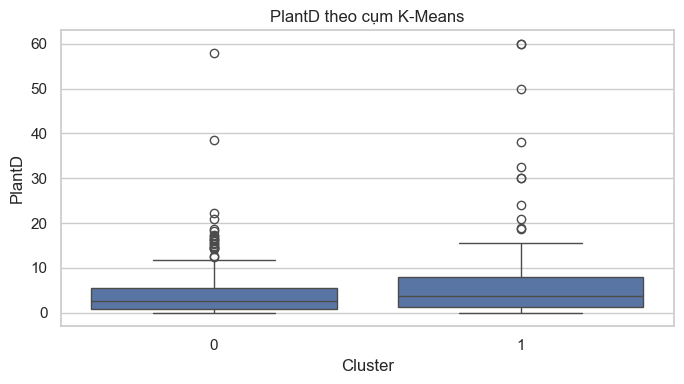

In [12]:
# Chuẩn bị dữ liệu môi trường cấp chuyến kéo
if env_for_join.duplicated(JOIN_KEYS).any():
    raise ValueError("Khóa môi trường vẫn bị trùng sau bước tổng hợp.")
env_cluster = clustered_samples.merge(env_for_join, on=JOIN_KEYS, how="left",
                                      validate="many_to_one", suffixes=("_bio", "_env"), indicator=True)
print("Số mẫu sau ghép:", len(env_cluster))
print("Số mẫu có thông tin môi trường:", int((env_cluster["_merge"] == "both").sum()))

# Thống kê mô tả cho từng biến môi trường
environment_candidates = [c for c in ["Depth_env", "Length", "TSpeed", "TDuration", "s.T", "b.T", "s.S", "b.S",
    "s.DOX", "b.DOX", "s.pH", "b.pH", "PlastD", "PlantD"] if c in env_cluster.columns]
env_summary_rows = []
for col in environment_candidates:
    env_cluster[col] = pd.to_numeric(env_cluster[col], errors="coerce")
    for cluster_id, group in env_cluster.groupby("Cluster"):
        values = group[col].dropna()
        env_summary_rows.append({"Variable": col, "Cluster": cluster_id, "N": len(values),
                                 "Mean": values.mean(), "Median": values.median()})
env_cluster_summary = pd.DataFrame(env_summary_rows)
display(env_cluster_summary)

# Kiểm định hai cụm; chỉ kiểm định khi mỗi cụm có ít nhất 2 quan sát hợp lệ
if len(np.unique(kmeans_labels)) == 2:
    test_rows = []
    for col in environment_candidates:
        group0 = env_cluster.loc[env_cluster.Cluster == 0, col].dropna()
        group1 = env_cluster.loc[env_cluster.Cluster == 1, col].dropna()
        if len(group0) >= 2 and len(group1) >= 2:
            stat, p = mannwhitneyu(group0, group1, alternative="two-sided")
            test_rows.append({"Variable": col, "N_Cluster_0": len(group0),
                              "Median_Cluster_0": group0.median(), "N_Cluster_1": len(group1),
                              "Median_Cluster_1": group1.median(), "p_value": p})
    if test_rows:
        env_test = pd.DataFrame(test_rows)
        # Benjamini–Hochberg FDR correction, triển khai trực tiếp để không cần thư viện bổ sung.
        p = env_test["p_value"].to_numpy()
        order = np.argsort(p)
        ranked = p[order]
        adjusted = np.minimum.accumulate((ranked * len(p) / np.arange(1, len(p)+1))[::-1])[::-1]
        p_adjusted = np.empty(len(p)); p_adjusted[order] = np.clip(adjusted, 0, 1)
        env_test["p_adjusted_BH"] = p_adjusted
        display(env_test.sort_values("p_adjusted_BH").round(4))
    else:
        print("Không có biến đủ quan sát để kiểm định.")
else:
    print("Kiểm định Mann–Whitney trong notebook này được thiết lập cho trường hợp K=2.")

# Boxplot với biến có ít nhất 60% dữ liệu hợp lệ
env_plot_cols = [c for c in environment_candidates if env_cluster[c].notna().mean() >= 0.60]
print("Biến môi trường đạt ngưỡng quan sát 60%:", env_plot_cols)
for col in env_plot_cols:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(data=env_cluster, x="Cluster", y=col, ax=ax)
    ax.set_title(f"{col} theo cụm K-Means")
    plt.tight_layout(); plt.show()

## CHƯƠNG 8. KẾT LUẬN, HẠN CHẾ VÀ TÁI LẬP

### Các câu hỏi cần trả lời trong báo cáo
1. Cấu trúc và chất lượng của bốn dataset như thế nào?
2. Vì sao s003 được chọn làm dữ liệu quần xã trọng tâm?
3. Khóa s002–s003 được xác minh ra sao? Có bao nhiêu khóa và bản ghi ghép thành công?
4. Raw abundance, Relative abundance và Hellinger cho kết quả khác nhau thế nào?
5. Vì sao chọn K theo Elbow và Silhouette? Silhouette có đủ cao để khẳng định cụm tách biệt rõ không?
6. Các cụm có đặc trưng Taxa và điều kiện môi trường như thế nào?
7. Kết quả có ổn định khi thay đổi random seed không?

### Hạn chế
- Ô 0 trong ma trận được diễn giải là không có bản ghi Taxa; cần xác nhận quy ước này từ metadata.
- Dòng Number thiếu không được tự động thay bằng 0; cần ghi nhận và kiểm tra nguyên nhân.
- s002 có nhiều biến thiếu; cỡ mẫu dùng trong từng kiểm định không giống nhau.
- Mann–Whitney U chỉ kiểm tra khác biệt phân phối giữa hai nhóm, không chứng minh quan hệ nhân quả.
- K-Means nhạy với lựa chọn K và đặc điểm dữ liệu; Silhouette thấp phản ánh ranh giới cụm có thể chưa rõ.
- PCA hai chiều có thể không thể hiện đầy đủ cấu trúc trong không gian nhiều chiều.
- s001 và s004 được phân tích khám phá riêng, không được ghép vào mô hình phân cụm do khác đơn vị quan sát/khóa.

### Gợi ý diễn giải
Không viết “mô hình chứng minh môi trường gây ra sự thay đổi quần xã”. Nên viết “các cụm có khác biệt mô tả/thống kê ở một số biến môi trường trong phạm vi dữ liệu khảo sát”.

In [13]:
# Xuất kết quả để sử dụng trong báo cáo và AquaBio Explorer
quality_report.to_csv(OUTPUT_DIR / "data_quality_report.csv", index=False, encoding="utf-8-sig")
sample_data.to_csv(OUTPUT_DIR / "sample_data.csv", index=False, encoding="utf-8-sig")
abundance_wide.to_csv(OUTPUT_DIR / "abundance_matrix.csv", index=False, encoding="utf-8-sig")
X_relative.to_csv(OUTPUT_DIR / "relative_matrix.csv", encoding="utf-8-sig")
X_hellinger.to_csv(OUTPUT_DIR / "hellinger_matrix.csv", encoding="utf-8-sig")
clustered_samples.to_csv(OUTPUT_DIR / "sample_cluster_labels.csv", index=False, encoding="utf-8-sig")
cluster_profile.to_csv(OUTPUT_DIR / "cluster_profile.csv", encoding="utf-8-sig")
cluster_taxa_mean.to_csv(OUTPUT_DIR / "cluster_taxa_profile.csv", encoding="utf-8-sig")
evaluation_table.to_csv(OUTPUT_DIR / "kmeans_evaluation.csv", index=False, encoding="utf-8-sig")
k_search.to_csv(OUTPUT_DIR / "kmeans_k_selection.csv", index=False, encoding="utf-8-sig")
comparison_table.to_csv(OUTPUT_DIR / "representation_comparison.csv", index=False, encoding="utf-8-sig")
stability_table.to_csv(OUTPUT_DIR / "kmeans_stability.csv", index=False, encoding="utf-8-sig")
env_cluster.to_csv(OUTPUT_DIR / "sample_environment_cluster.csv", index=False, encoding="utf-8-sig")
if "env_test" in globals():
    env_test.to_csv(OUTPUT_DIR / "environment_cluster_tests.csv", index=False, encoding="utf-8-sig")

print("========== TÓM TẮT ĐỒ ÁN ==========")
print("Số mẫu sinh học:", len(sample_data))
print("Số mẫu hợp lệ phân cụm:", len(X_hellinger))
print("Số Taxa:", X_hellinger.shape[1])
print("Số bản ghi s003 ghép được thông tin môi trường:", int((bio_linked["_merge"] == "both").sum()))
print("Số mẫu độc lập có khóa môi trường:", int(env_cluster[JOIN_KEYS].drop_duplicates().shape[0]))
print("K được chọn:", best_k)
print("Silhouette:", round(float(evaluation_table.loc[0, "Silhouette"]), 4))
print("Thư mục kết quả:", OUTPUT_DIR.resolve())

========== TÓM TẮT ĐỒ ÁN ==========
Số mẫu sinh học: 527
Số mẫu hợp lệ phân cụm: 527
Số Taxa: 49
Số bản ghi s003 ghép được thông tin môi trường: 4161
Số mẫu độc lập có khóa môi trường: 527
K được chọn: 2
Silhouette: 0.2597
Thư mục kết quả: D:\LEQUY\Cá\outputs
